In [1]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Works in Google Colab (/content) and locally (CSV in the same folder)
matches = glob.glob("/content/Food_Delivery_Customer_Churn*.csv") + glob.glob("Food_Delivery_Customer_Churn*.csv")
if not matches:
    raise FileNotFoundError("Place Food_Delivery_Customer_Churn.csv next to this notebook (or upload it in Colab).")
df = pd.read_csv(matches[0])
print("Dataset loaded:", matches[0], df.shape)


Dataset loaded: Food_Delivery_Customer_Churn.csv (500, 11)


In [2]:

# Select numerical features for clustering

features = [
    "Age",
    "Orders_Per_Month",
    "Average_Order_Value",
    "Tenure_Months"
]

X = df[features].copy()

# Check missing values
print("Missing Values Before Preprocessing:")
print(X.isnull().sum())

# Handle missing values using median
X = X.fillna(X.median())

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nFeature selection and preprocessing completed!")


Missing Values Before Preprocessing:
Age                    0
Orders_Per_Month       0
Average_Order_Value    0
Tenure_Months          0
dtype: int64

Feature selection and preprocessing completed!


In [3]:

print("===== PREPROCESSING OUTPUT =====")

print("Total Records:", X.shape[0])
print("Selected Features:", X.shape[1])

print("\nSelected Feature Names:")
print(features)

print("\nMissing Values After Preprocessing:")
print(X.isnull().sum().sum())

print("\nStandardized Dataset Shape:")
print(X_scaled.shape)

print("\nFirst 5 Standardized Records:")
print(pd.DataFrame(X_scaled, columns=features).head())


===== PREPROCESSING OUTPUT =====
Total Records: 500
Selected Features: 4

Selected Feature Names:
['Age', 'Orders_Per_Month', 'Average_Order_Value', 'Tenure_Months']

Missing Values After Preprocessing:
0

Standardized Dataset Shape:
(500, 4)

First 5 Standardized Records:
        Age  Orders_Per_Month  Average_Order_Value  Tenure_Months
0  1.334884         -1.497225            -1.776060      -1.558099
1  0.525569         -0.448013             0.191315      -1.027205
2 -0.607472          0.426330             0.375651       0.489636
3  1.658610          0.426330            -1.481121       1.399741
4 -1.173992         -1.672093            -0.609712       0.565478


In [4]:

# Calculate inertia for different K values

inertia_values = []
k_values = range(1, 11)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

print("Inertia calculated for K = 1 to 10")
print(inertia_values)


Inertia calculated for K = 1 to 10
[2000.0, 1609.0977167207302, 1353.646756599703, 1166.0862257194021, 1012.0792045362089, 915.3085916564701, 815.5832457411907, 730.0099986391779, 681.7436801684801, 638.8347762525086]


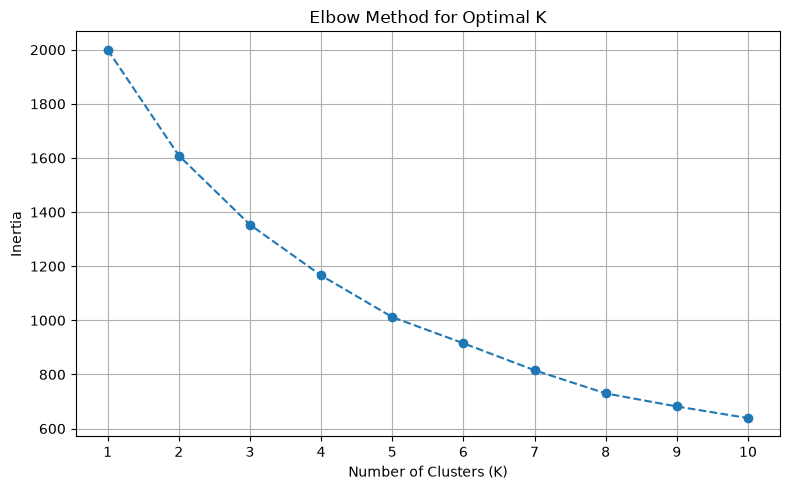

In [5]:

# Plot Elbow Method graph

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia_values,
    marker='o',
    linestyle='--'
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.xticks(k_values)
plt.grid(True)

plt.tight_layout()
plt.show()


In [6]:

# Apply K-Means clustering with K = 3

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit the model and predict cluster labels
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to original dataset
df["Cluster"] = cluster_labels

print("K-Means clustering completed successfully!")


K-Means clustering completed successfully!


In [7]:

# Display cluster counts

print("===== NUMBER OF CUSTOMERS IN EACH CLUSTER =====")

print(df["Cluster"].value_counts().sort_index())

# Display cluster centroids
centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=features
)

print("\n===== STANDARDIZED CLUSTER CENTROIDS =====")
print(centroids.round(3))


===== NUMBER OF CUSTOMERS IN EACH CLUSTER =====
Cluster
0    184
1    164
2    152
Name: count, dtype: int64

===== STANDARDIZED CLUSTER CENTROIDS =====
     Age  Orders_Per_Month  Average_Order_Value  Tenure_Months
0  0.308            -0.197                0.416         -0.914
1  0.400            -0.533               -0.643          0.596
2 -0.805             0.814                0.190          0.463


In [8]:

# Calculate clustering evaluation metrics

sil_score = silhouette_score(
    X_scaled,
    cluster_labels
)

inertia = kmeans.inertia_

db_index = davies_bouldin_score(
    X_scaled,
    cluster_labels
)

print("===== CLUSTERING EVALUATION =====")

print("Number of Clusters:", 3)

print("Silhouette Score:", round(sil_score, 4))

print("Inertia:", round(inertia, 4))

print("Davies-Bouldin Index:", round(db_index, 4))


===== CLUSTERING EVALUATION =====
Number of Clusters: 3
Silhouette Score: 0.1869
Inertia: 1353.6468
Davies-Bouldin Index: 1.6517


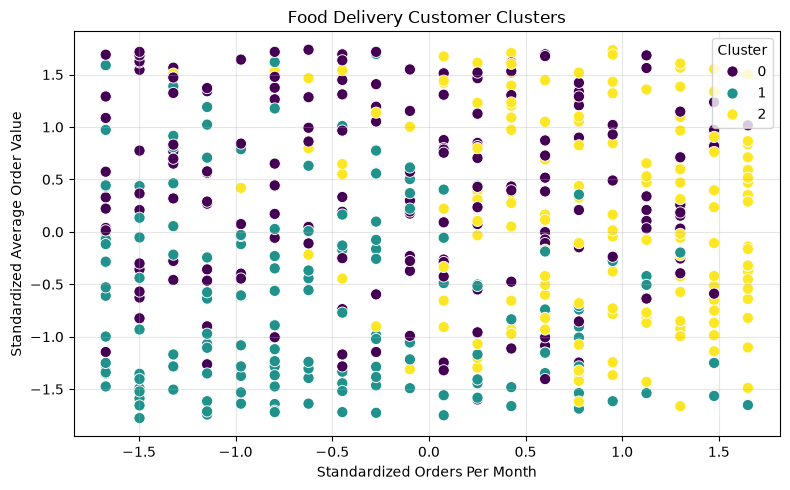

In [9]:

# Prepare data for cluster visualization

plot_data = pd.DataFrame(
    X_scaled,
    columns=features
)

plot_data["Cluster"] = cluster_labels

# Create scatter plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=plot_data,
    x="Orders_Per_Month",
    y="Average_Order_Value",
    hue="Cluster",
    palette="viridis",
    s=65
)

plt.title("Food Delivery Customer Clusters")
plt.xlabel("Standardized Orders Per Month")
plt.ylabel("Standardized Average Order Value")

plt.legend(title="Cluster")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [10]:

# Create dataset with cluster labels

clustered_data = X.copy()

clustered_data["Cluster"] = cluster_labels

# Calculate mean of each feature
cluster_means = clustered_data.groupby(
    "Cluster"
)[features].mean()

# Calculate number of customers
cluster_sizes = clustered_data.groupby(
    "Cluster"
).size()

# Combine results
cluster_summary = cluster_means.copy()

cluster_summary["Number_of_Customers"] = cluster_sizes

print("Cluster-wise analysis completed successfully!")


Cluster-wise analysis completed successfully!


In [11]:

print("===== CLUSTER-WISE CUSTOMER ANALYSIS =====")

print(cluster_summary.round(2))


===== CLUSTER-WISE CUSTOMER ANALYSIS =====
           Age  Orders_Per_Month  Average_Order_Value  Tenure_Months  \
Cluster                                                                
0        43.32              9.43               804.90          12.49   
1        44.45              7.51               489.13          32.40   
2        29.56             15.22               737.76          30.65   

         Number_of_Customers  
Cluster                       
0                        184  
1                        164  
2                        152  


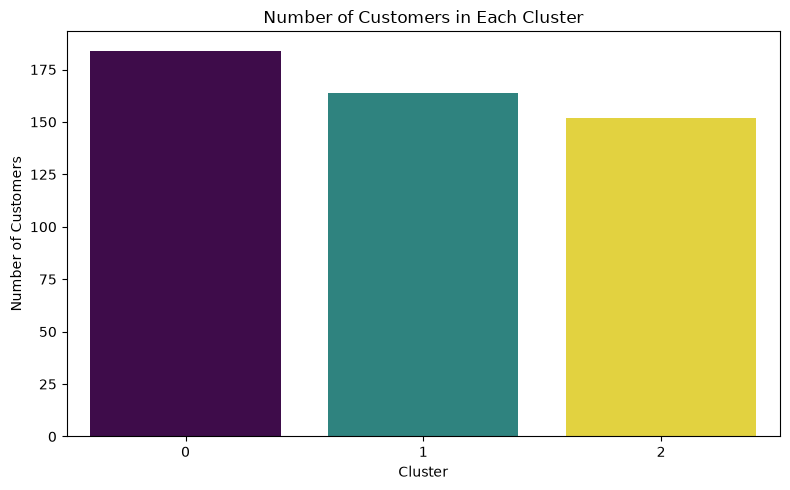

In [12]:

# Plot cluster sizes

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Cluster",
    hue="Cluster",
    palette="viridis",
    legend=False
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


In [13]:

# Final K-Means evaluation summary

print("===== FINAL K-MEANS EVALUATION SUMMARY =====")

print("\nNumber of Clusters:", kmeans.n_clusters)

print("Total Customers:", len(df))

print("Silhouette Score:", round(
    silhouette_score(X_scaled, cluster_labels), 4
))

print("Inertia:", round(kmeans.inertia_, 4))

print("Davies-Bouldin Index:", round(
    davies_bouldin_score(X_scaled, cluster_labels), 4
))

print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

print("\nK-Means Clustering Completed Successfully!")


===== FINAL K-MEANS EVALUATION SUMMARY =====

Number of Clusters: 3
Total Customers: 500
Silhouette Score: 0.1869
Inertia: 1353.6468
Davies-Bouldin Index: 1.6517

Cluster Distribution:
Cluster
0    184
1    164
2    152
Name: count, dtype: int64

K-Means Clustering Completed Successfully!


In [14]:
# Supplementary: choosing K - inertia (elbow) and silhouette score for every K
k_table = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    sil = silhouette_score(X_scaled, km.labels_) if k > 1 else float("nan")
    k_table.append((k, round(km.inertia_, 1), round(sil, 3)))

k_df = pd.DataFrame(k_table, columns=["K", "Inertia", "Silhouette"])
k_df["Inertia drop"] = (-k_df["Inertia"].diff()).round(1)

print("===== K SELECTION TABLE =====")
print(k_df.to_string(index=False))


===== K SELECTION TABLE =====
 K  Inertia  Silhouette  Inertia drop
 1   2000.0         NaN           NaN
 2   1609.1       0.189         390.9
 3   1353.6       0.187         255.5
 4   1166.1       0.199         187.5
 5   1012.1       0.210         154.0
 6    915.3       0.216          96.8
 7    815.6       0.223          99.7
 8    730.0       0.243          85.6
 9    681.7       0.232          48.3
10    638.8       0.234          42.9
